In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [4]:
df = pd.read_csv('ML/sales_data_sample.csv', encoding = 'ISO-8859-1')

In [5]:
df.head()

,ORDERNUMBER,QUANTITYORDERED,PRICEEACH,ORDERLINENUMBER,SALES,ORDERDATE,STATUS,QTR_ID,MONTH_ID,YEAR_ID,...,ADDRESSLINE1,ADDRESSLINE2,CITY,STATE,POSTALCODE,COUNTRY,TERRITORY,CONTACTLASTNAME,CONTACTFIRSTNAME,DEALSIZE
0,10107,30,95.70,2,2871.00,2/24/2003 0:00,Shipped,1,2,2003,...,897 Long Airport Avenue,NaN,NYC,NY,10022,USA,NaN,Yu,Kwai,Small
1,10121,34,81.35,5,2765.90,5/7/2003 0:00,Shipped,2,5,2003,...,59 rue de l'Abbaye,NaN,Reims,NaN,51100,France,EMEA,Henriot,Paul,Small
2,10134,41,94.74,2,3884.34,7/1/2003 0:00,Shipped,3,7,2003,...,27 rue du Colonel Pierre Avia,NaN,Paris,NaN,75508,France,EMEA,Da Cunha,Daniel,Medium
3,10145,45,83.26,6,3746.70,8/25/2003 0:00,Shipped,3,8,2003,...,78934 Hillside Dr.,NaN,Pasadena,CA,90003,USA,NaN,Young,Julie,Medium
4,10159,49,100.00,14,5205.27,10/10/2003 0:00,Shipped,4,10,2003,...,7734 Strong St.,NaN,San Francisco,CA,NaN,USA,NaN,Brown,Julie,Medium


In [6]:
features = ["QUANTITYORDERED", "PRICEEACH", "SALES"]
data = df[features].copy()
data = data.dropna()

In [7]:
for column in features:
    Q1 = data[column].quantile(0.25)
    Q3 = data[column].quantile(0.75)
    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = data[
        (data[column] < lower_bound) |
        (data[column] > upper_bound)
    ]

    print(f"\n{column}")
    print("Q1:", Q1)
    print("Q3:", Q3)
    print("IQR:", IQR)
    print("Lower Bound:", lower_bound)
    print("Upper Bound:", upper_bound)
    print("Number of Outliers:", len(outliers))


QUANTITYORDERED
Q1: 27.0
Q3: 43.0
IQR: 16.0
Lower Bound: 3.0
Upper Bound: 67.0
Number of Outliers: 8

PRICEEACH
Q1: 68.86
Q3: 100.0
IQR: 31.14
Lower Bound: 22.15
Upper Bound: 146.71
Number of Outliers: 0

SALES
Q1: 2203.4300000000003
Q3: 4508.0
IQR: 2304.5699999999997
Lower Bound: -1253.4249999999993
Upper Bound: 7964.855
Number of Outliers: 81


In [8]:
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

In [9]:
scaler = StandardScaler()
X = scaler.fit_transform(data)

In [10]:
inertia = []

In [11]:
for k in range(1, 11):
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )
    kmeans.fit(X)
    inertia.append(kmeans.inertia_)

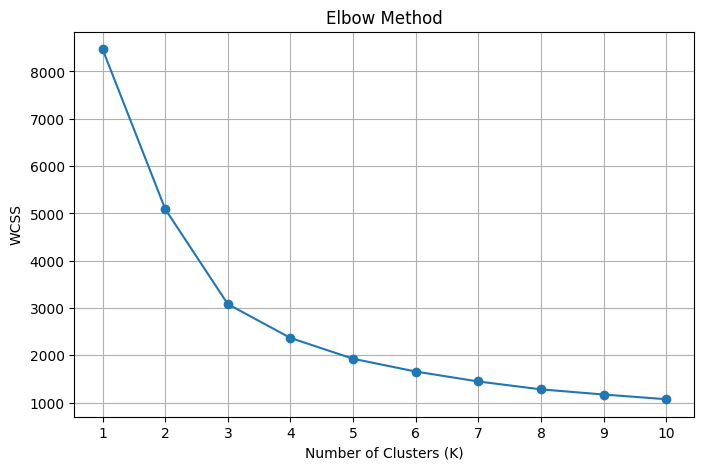

In [12]:
plt.figure(figsize=(8, 5))
plt.plot(range(1, 11), inertia, marker="o")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("WCSS")
plt.title("Elbow Method")
plt.xticks(range(1, 11))
plt.grid()
plt.show()

In [18]:
k = 4

In [19]:
kmeans = KMeans(
    n_clusters=k,
    random_state=42,
    n_init=10
)

In [20]:
data["Cluster"] = kmeans.fit_predict(X)

In [21]:
silhouette = silhouette_score(X, data["Cluster"])

print("\nSilhouette Score:", silhouette)


Silhouette Score: 0.4218778791156011


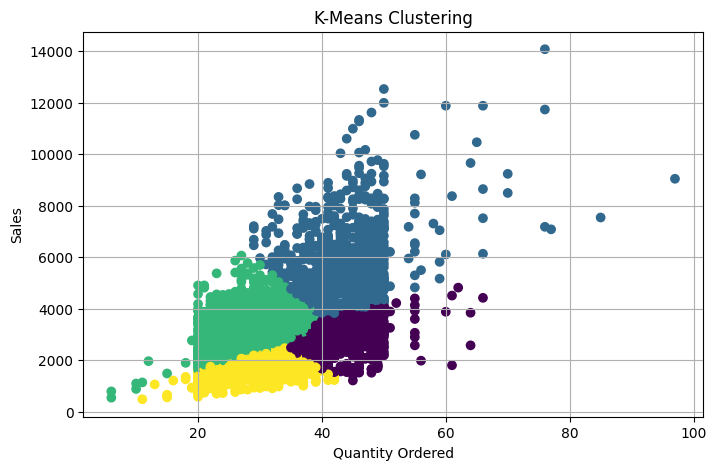

In [22]:
plt.figure(figsize=(8, 5))
plt.scatter(
    data["QUANTITYORDERED"],
    data["SALES"],
    c=data["Cluster"],
    cmap="viridis"
)

plt.xlabel("Quantity Ordered")
plt.ylabel("Sales")
plt.title("K-Means Clustering")
plt.grid()
plt.show()
